In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

In [10]:
df = pd.read_csv("data/process_data.csv")

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_column = "Machine failure"

X = df[feature_columns]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 6)
Testing data: (2000, 6)


Createing  training and validation sets

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nFailure distribution in fitting data:")
print(y_fit.value_counts(normalize=True).round(3))

print("\nFailure distribution in validation data:")
print(y_val.value_counts(normalize=True).round(3))

Model fitting data: (6400, 6)
Validation data: (1600, 6)

Failure distribution in fitting data:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64

Failure distribution in validation data:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical features
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Categorical features
categorical_features = ["Type"]

# Create transformations
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


creating a baseline model


In [12]:
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_fit, y_fit)

dummy_predictions = dummy_model.predict(X_val)

print(classification_report(
    y_val,
    dummy_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1546
           1       0.00      0.00      0.00        54

    accuracy                           0.97      1600
   macro avg       0.48      0.50      0.49      1600
weighted avg       0.93      0.97      0.95      1600



Building the  Logistic Regression pipeline

In [16]:
logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_fit, y_fit)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Model prediction and evaluation

In [17]:
# Predict machine failure (0 or 1)
y_val_pred = logistic_model.predict(X_val)

# Get probability of machine failure
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Actual values:")
print(y_val.iloc[:10].values)

print("\nPredicted values:")
print(y_val_pred[:10])

print("\nFailure probabilities:")
print(np.round(y_val_prob[:10], 3))

Actual values:
[0 0 0 0 0 1 0 0 0 0]

Predicted values:
[0 1 0 1 0 0 1 0 0 1]

Failure probabilities:
[0.016 0.795 0.007 0.575 0.019 0.324 0.893 0.134 0.187 0.548]


Calculate evaluation metrics

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1 Score": f1_score(y_val, y_val_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_val, y_val_prob),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob)
}

print(" LOGISTIC REGRESSION RESULTS ")

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

 LOGISTIC REGRESSION RESULTS 
Accuracy: 0.8231
Precision: 0.1433
Recall: 0.8519
F1 Score: 0.2453
PR-AUC: 0.4197
ROC-AUC: 0.8927


confusion metrix

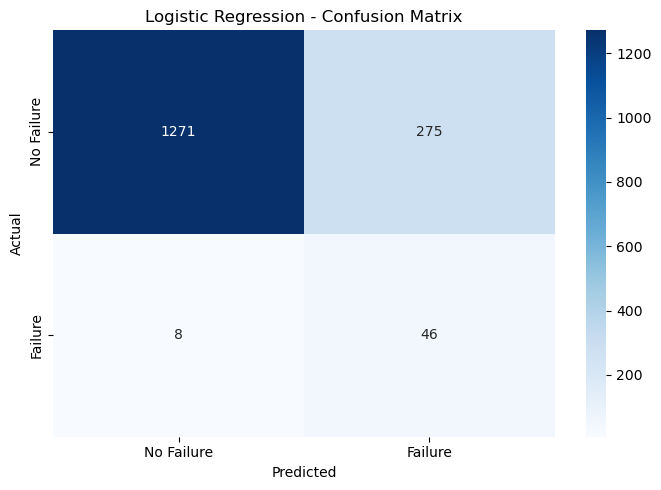

In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

classification report 

In [21]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1546
     Failure       0.14      0.85      0.25        54

    accuracy                           0.82      1600
   macro avg       0.57      0.84      0.57      1600
weighted avg       0.97      0.82      0.88      1600



precision call curve


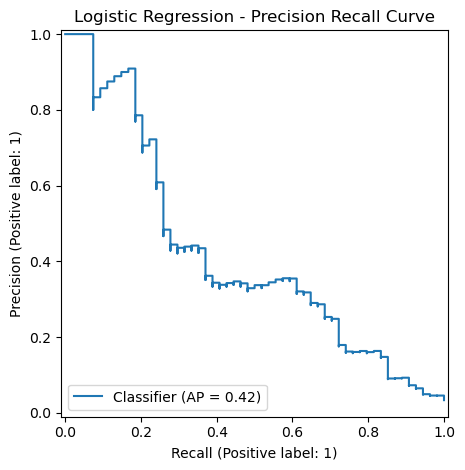

In [22]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_val_prob
)

plt.title("Logistic Regression - Precision Recall Curve")
plt.tight_layout()
plt.show()